# The referee's verdict on 256 trend rules

**Author:** Franz Triebe · **Date:** 2026-10-11 · **Status:** final

**Question.** A naive researcher tries 256 trend timing rules on SPY and reports the best one. How much of that winner's backtest should we believe once we account for the search?

**Data.** SPY daily adjusted closes from Yahoo Finance (dividends reinvested) and the daily one month T bill rate from the Ken French data library, retrieved 2026-10-11. Common sample April 1994 to October 2026.

> **Key findings**
> 1. **Verdict: not distinguishable from luck.** The naive winner `x50_250_lf_vt_w` has a Sharpe ratio of 0.68, but the best of 256 useless trials would be expected to show about **0.65**. The deflated Sharpe ratio is **0.58**, far below the 0.80 needed for even a weak verdict. A two day lag or 10 bp costs do not change the verdict; at 10 bp the hurdle (0.70) is above the winner.
> 2. **The holdout agrees.** Selected on 1994 to 2015 only, the best rule earned a Sharpe ratio of **0.65** afterwards, below buy and hold's **0.75** and only rank 80 of 256. Buy and hold ended with more wealth (30.9 against 24.1 dollars per dollar invested).
> 3. **What does survive is the type of rule, not the rule.** PBO is low (**0.10**): slow, long/flat trend rules reliably beat the rest of the family, and they cut the worst drawdown from 55% to about 20%. How confident to be depends on how many independent tries we count: DSR 0.58 with 256 trials, 0.72 with 105, 0.998 with 2.5.

**Contents**
1. [Setup](#1.-Setup)
2. [Data](#2.-Data)
3. [Method](#3.-Method)
4. [Results](#4.-Results)
5. [Conclusions](#5.-Conclusions)
6. [Appendix: environment](#6.-Appendix:-environment)

## 1. Setup

In [1]:
import platform
from importlib.metadata import version
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import quantlab
from IPython.display import Markdown, display
from quantlab import (
    acad,
    backtest,
    data,
    pipeline,
    plotting,
    stats,
    strategies,
    validation,
)

In [2]:
TICKER = "SPY"  # Yahoo symbol; adjusted closes make it a total return series
START = "1993-01-01"  # first date to load; trials start after their warmup
LAG = 1  # trading days between a decision at the close and the first return it earns
COST_BPS = 5.0  # cost per unit of one way turnover, in basis points
N_BLOCKS = 16  # CSCV blocks for PBO
ALPHA = 0.05  # significance level for MinTRL
HOLDOUT_SPLIT = 2 / 3  # select on the first two thirds, test on the last third
ROBUSTNESS = [(2, 5.0), (1, 10.0)]  # (lag, cost in bp) to rerun the whole referee with
ANN_FACTOR = 252  # trading days per year
PROJECT = "p01"  # project name in the trial ledger
REFRESH = False  # True downloads fresh data instead of using the cache in data/
OUTPUT_DIR = Path(quantlab.__file__).resolve().parents[1] / "output" / "p01"

In [3]:
acad.apply_style()
pd.options.display.float_format = "{:,.4f}".format
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
NOTE = "Notes: SPY daily returns (Yahoo Finance adjusted close), excess over the one month T bill (Ken French), April 1994 to October 2026, one day lag, 5 bp costs."

## 2. Data

Same data and the same 256 trials as notebook 03.

In [4]:
returns = data.load_yahoo(TICKER, start=START, refresh=REFRESH)
rf_published = data.load_rf_daily(refresh=REFRESH)
rf = rf_published.reindex(returns.index).ffill()
n_rf_filled = int((returns.index > rf_published.index[-1]).sum())
prices = (1 + returns).cumprod()
trials = strategies.build_trials(prices)
assert len(trials) == 256 and not rf.isna().any()
print(
    f"{len(returns):,} daily returns, {len(trials)} trials; risk free rate carried forward for {n_rf_filled} days"
)

8,481 daily returns, 256 trials; risk free rate carried forward for 28 days


## 3. Method

The verdict rules are fixed **before** looking at the results (PLAN.md honesty rule):

| Verdict | Condition |
| --- | --- |
| Strong | DSR at least 0.95 and PBO at most 0.20 |
| Weak | DSR at least 0.80 and PBO at most 0.50, but not Strong |
| Not distinguishable from luck | everything else |

The headline DSR counts every distinct trial in the ledger (here 256). The DSR with the two effective trial counts from notebook 03 is reported next to it, but does not decide the verdict. The thresholds are conventions, not laws.

Steps: (1) backtest all 256 trials with a one day lag and 5 bp costs; (2) pick the trial with the best full sample Sharpe ratio, as a naive researcher would; (3) run every referee tool on it; (4) a holdout check that selects on 1994 to 2015 only; (5) rerun everything with a two day lag and with 10 bp costs.

In [5]:
run = pipeline.run_referee(
    trials,
    returns,
    project=PROJECT,
    data_label=TICKER,
    rf=rf,
    lag=LAG,
    cost_bps=COST_BPS,
    n_blocks=N_BLOCKS,
    alpha=ALPHA,
)
report = run["report"]
excess = run["excess"]
winner = run["selected"]
common_start = max(w.first_valid_index() for w in trials.values())
benchmark = backtest.run(
    pd.Series(1.0, index=returns.index).where(returns.index >= common_start),
    returns,
    lag=LAG,
    cost_bps=COST_BPS,
    rf=rf,
).loc[excess.index]
assert not benchmark.isna().any().any()
print(
    f"Naive winner: {winner}; ledger counts {run['n_ledger']} trials for {run['data_id']}"
)

Naive winner: x50_250_lf_vt_w; ledger counts 257 trials for SPY 1993-02-01 2026-10-09


## 4. Results

### 4.1 Buy and hold against the naive winner

In [6]:
winner_result = run["results"][winner]
side_by_side = pd.DataFrame(
    {
        "buy and hold": stats.summary(
            benchmark["excess"],
            total=benchmark["total"],
            position=benchmark["position"],
        ),
        f"naive winner: {winner}": stats.summary(
            winner_result["excess"],
            total=winner_result["total"],
            position=winner_result["position"],
        ),
    }
)
percent_rows = [
    "ann_mean_excess",
    "ann_geo_total",
    "ann_vol",
    "max_drawdown",
    "hit_rate",
    "time_in_market",
]
display(
    side_by_side.style.format("{:.2f}").format(
        "{:.1%}", subset=pd.IndexSlice[percent_rows, :]
    )
)

,buy and hold,naive winner: x50_250_lf_vt_w
ann_mean_excess,9.9%,8.0%
ann_geo_total,11.1%,10.3%
ann_vol,18.8%,11.7%
sharpe,0.53,0.68
sortino,0.75,0.95
max_drawdown,-55.2%,-20.2%
calmar,0.20,0.51
skew,-0.01,-0.51
kurtosis,14.60,8.79
hit_rate,54.0%,54.8%


**Reading the table.** The winner earns *less* than buy and hold: 8.0% a year above cash instead of 9.9%, and 10.3% a year in total instead of 11.1%. Its higher Sharpe ratio (0.68 against 0.53) comes entirely from lower risk: volatility of 11.7% instead of 18.8%, and a worst drawdown of 20% instead of 55%. It is invested 78% of the time and trades about once a year. Its returns are more negatively skewed ($-0.51$): it gives up the sharp rebounds that follow crashes.

### 4.2 The referee table

In [7]:
referee_md = validation.report_to_markdown(report)
display(Markdown(referee_md))

**Selected trial:** `x50_250_lf_vt_w` · 1994-04-11 to 2026-10-09 (32.5 years, T = 8,180)

| Measure | Value | Meaning |
| --- | --- | --- |
| Sharpe ratio (annualized) | 0.68 | before any correction |
| t statistic, iid / Newey West (10 lags) | 3.90 / 4.36 | above 2 is the usual bar, above 3 after a search |
| Skewness / kurtosis | -0.51 / 8.8 | normal is 0 / 3 |
| PSR(0) | 1.000 | probability the true Sharpe is above 0, ignoring the search |
| Trials: this run / ledger / used | 256 / 257 / 257 | |
| Effective trials: avg corr / eigen | 104.9 / 2.5 | independent bets among the trials |
| Hurdle SR0 (annualized): raw N / avg corr / eigen | 0.65 / 0.58 / 0.16 | expected best Sharpe of that many useless trials |
| DSR: raw N / avg corr / eigen | 0.579 / 0.720 / 0.998 | probability the true Sharpe beats the hurdle |
| MinTRL in years vs 0 / vs SR0 (actual 32.5) | 5.9 / 2221.5 | track record needed at 95% confidence |
| Haircut Sharpe, Bonferroni | 0.40 (42% haircut) | Sharpe left after correcting for 256 tests |
| Haircut Sharpe, Holm | 0.40 (42% haircut) | Sharpe left after correcting for 256 tests |
| Haircut Sharpe, BHY | 0.42 (39% haircut) | Sharpe left after correcting for 256 tests |
| PBO (CSCV, 16 blocks, 12,870 splits) | 0.10 | share of splits where the IS winner is at or below the OOS median |
| P(OOS loss) / degradation slope | 0.00 / -0.90 | slope 1 means IS performance carries over fully |

**Verdict: Not distinguishable from luck.** Strong needs DSR at least 0.95 and PBO at most 0.2; Weak needs DSR at least 0.8 and PBO at most 0.5. These thresholds are conventions, not laws.

**Reading the table.** Taken on its own, the winner looks excellent: a t statistic of 3.9 (4.4 with Newey West), PSR(0) of 1.00, and only 5.9 years of track record needed to show a Sharpe ratio above 0, against 32.5 available.

The picture changes once the search is counted. The 256 trial Sharpe ratios spread so widely that the best of 256 *useless* rules would be expected to reach about 0.65. The winner's 0.68 is barely above that, so the DSR is only 0.58: a 58% probability that its true Sharpe ratio beats the luck hurdle, little better than a coin flip. Proving that small edge at 95% confidence would take about 2,200 years of data (MinTRL against $SR_0$).

The multiple testing haircuts tell the same story from another angle: after Bonferroni, Holm or BHY corrections for 256 tests, about 0.40 of the Sharpe ratio is left. That is still above 0, but below the 0.53 of buy and hold, which needs no search at all.

PBO is low (0.10), and Section 4.4 explains why that does not rescue the winner. Under the rules fixed in Section 3, DSR 0.58 means **not distinguishable from luck**.

### 4.3 Figure F2: the winner against the luck hurdle

The histogram of all 256 Sharpe ratios, with buy and hold, the hurdle $SR_0$ (the Sharpe ratio the best of 256 useless trials would be expected to show, given how widely the trials' Sharpe ratios spread) and the winner.

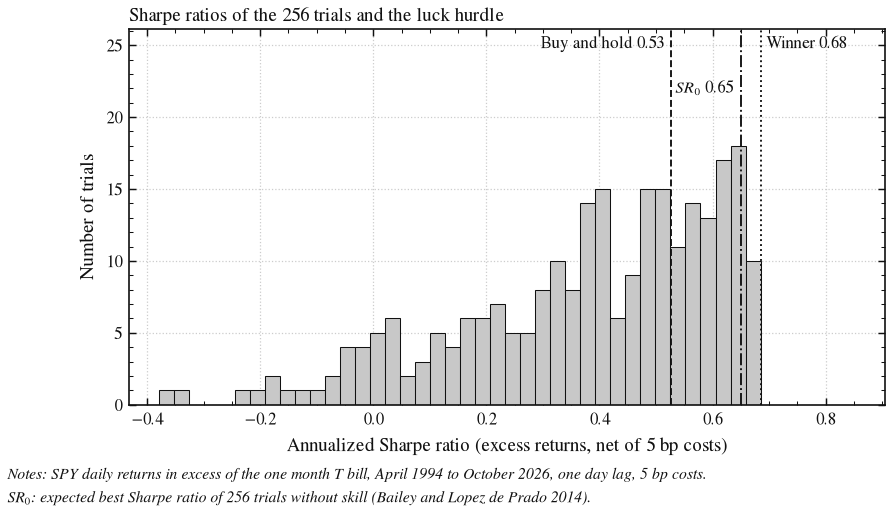

In [8]:
sharpes = excess.mean() / excess.std() * np.sqrt(ANN_FACTOR)
hurdle = report["sr0_ann"]["raw"]
bh_sharpe = side_by_side.loc["sharpe", "buy and hold"]
fig, ax = acad.new_fig("full", aspect=0.5)
counts, _, _ = ax.hist(sharpes, bins=40, **acad.hist_kw())
ax.set_ylim(0, counts.max() * 1.45)
plotting.reference_line(ax, bh_sharpe, f"Buy and hold {bh_sharpe:.2f}", side="left")
plotting.reference_line(
    ax, hurdle, f"$SR_0$ {hurdle:.2f}", linestyle="-.", side="left", ypos=0.88
)
plotting.reference_line(
    ax, report["sr_ann"], f"Winner {report['sr_ann']:.2f}", linestyle=":"
)
ax.set_xlim(right=report["sr_ann"] + 0.22)
ax.set_xlabel("Annualized Sharpe ratio (excess returns, net of 5 bp costs)")
ax.set_ylabel("Number of trials")
ax.set_title("Sharpe ratios of the 256 trials and the luck hurdle")
acad.source_note(
    fig,
    "Notes: SPY daily returns in excess of the one month T bill, April 1994 to October 2026, one day lag, 5 bp costs.\n$SR_0$: expected best Sharpe ratio of 256 trials without skill (Bailey and Lopez de Prado 2014).",
)
acad.save(fig, "f2_sharpe_hurdle", outdir=OUTPUT_DIR)
plt.show()

**Figure 1.** The best of 256 rules (0.68) barely clears the luck hurdle of 0.65.

**Reading the chart.** The winner (dotted line) sits just to the right of the hurdle (dash dot line). The hurdle is high because the trials' Sharpe ratios spread from $-0.38$ to 0.68: with that much dispersion, the maximum of 256 draws is large even without skill. Buy and hold sits to the left of both.

### 4.4 Figure F3: probability of backtest overfitting

Left: for each of the 12,870 CSCV splits, the logit of the in sample winner's out of sample rank; values at or below 0 mean the winner landed at or below the median. Right: the winner's in sample against out of sample Sharpe ratio in each split, with the fitted degradation line.

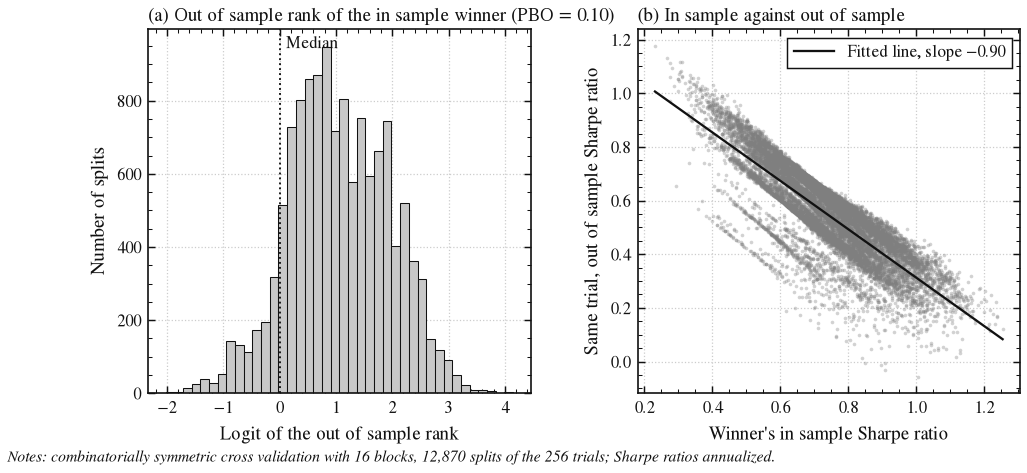

In [9]:
pbo = report["pbo"]
is_ann, oos_ann = (
    pbo["is_sr"] * np.sqrt(ANN_FACTOR),
    pbo["oos_sr"] * np.sqrt(ANN_FACTOR),
)
fig, (ax_l, ax_r) = acad.new_fig(
    "wide", aspect=0.42, ncols=2, gridspec_kw={"wspace": 0.28}
)
ax_l.hist(pbo["logits"], bins=40, **acad.hist_kw())
plotting.reference_line(ax_l, 0, "Median", linestyle=":")
ax_l.set_xlabel("Logit of the out of sample rank")
ax_l.set_ylabel("Number of splits")
acad.panel_title(
    ax_l, "a", f"Out of sample rank of the in sample winner (PBO = {pbo['pbo']:.2f})"
)
ax_r.scatter(is_ann, oos_ann, s=3, color=acad.GREY, alpha=0.35, linewidth=0)
grid = np.linspace(is_ann.min(), is_ann.max(), 50)
ax_r.plot(
    grid,
    (pbo["intercept"] + pbo["slope"] * grid / np.sqrt(ANN_FACTOR))
    * np.sqrt(ANN_FACTOR),
    color=acad.INK,
    linestyle="-",
    label=f"Fitted line, slope {pbo['slope']:.2f}".replace("-", "−"),
)
ax_r.set_xlabel("Winner's in sample Sharpe ratio")
ax_r.set_ylabel("Same trial, out of sample Sharpe ratio")
acad.panel_title(ax_r, "b", "In sample against out of sample")
ax_r.legend(loc="upper right")
acad.source_note(
    fig,
    "Notes: combinatorially symmetric cross validation with 16 blocks, 12,870 splits of the 256 trials; Sharpe ratios annualized.",
)
acad.save(fig, "f3_pbo", outdir=OUTPUT_DIR)
plt.show()

**Figure 2.** PBO is only 0.10, yet a higher in sample Sharpe ratio goes with a lower out of sample one.

**Reading the chart.** Panel (a): in 90% of the splits the in sample winner ends above the out of sample median, so PBO is only 0.10. Choosing the best backtest within this family is far better than choosing at random. The reason is that the family contains many clearly worse variants (long/short and fast rules) that never win in sample. What is learnable is the *type* of rule: slow, long/flat trend following.

Panel (b): the slope is $-0.90$, so a higher in sample Sharpe ratio goes with a *lower* out of sample one. In sample and out of sample are complementary halves of the same 32 years. A split whose in sample half contains the 2000 to 2002 and 2008 crashes, where trend rules shine, leaves the calm bull markets for the out of sample half, where they lag. The winner's performance is concentrated in a few crash periods. The out of sample Sharpe ratio is still positive in every split (P(OOS loss) = 0), because a long/flat rule earns the equity premium most of the time.

### 4.5 Holdout: select on 1994 to 2015, test on 2015 to 2026

A researcher who had kept the last third of the data aside would have picked the best trial on the first two thirds only and then looked at how it did afterwards.

In [10]:
hold = validation.holdout(excess, benchmark["excess"], split=HOLDOUT_SPLIT)
holdout_table = pd.Series(
    {
        "trial selected on the first two thirds": hold["selected"],
        "first trading day of the holdout": f"{hold['split_date']:%Y-%m-%d}",
        "its Sharpe ratio before the split": f"{hold['train_sr']:.2f}",
        "its Sharpe ratio in the holdout": f"{hold['test_sr']:.2f}",
        "buy and hold in the holdout": f"{hold['test_sr_benchmark']:.2f}",
        "median trial in the holdout": f"{hold['test_sr_median_trial']:.2f}",
        "its rank in the holdout": f"{hold['test_rank']} of {hold['n_trials']}",
    }
).to_frame("holdout check")
display(holdout_table)

,holdout check
trial selected on the first two thirds,sma300_lf_vt_w
first trading day of the holdout,2015-12-04
its Sharpe ratio before the split,0.68
its Sharpe ratio in the holdout,0.65
buy and hold in the holdout,0.75
median trial in the holdout,0.52
its rank in the holdout,80 of 256


**Reading the table.** A researcher who kept 2015 to 2026 aside would have picked `sma300_lf_vt_w`, the volatility targeted 300 day rule. It held up against its own past (0.65 against 0.68), but in the same years buy and hold earned 0.75, and 79 other trials did better. Its edge over buy and hold did not carry over.

### 4.6 Figure F4: wealth of the winner and buy and hold

Growth of one dollar (total returns, log scale). The shaded area is the holdout period.

In [11]:
totals = {
    f"Naive winner ({winner})": winner_result["total"],
    "Buy and hold": benchmark["total"],
    f"Holdout pick ({hold['selected']})": run["results"][hold["selected"]]["total"],
}
for label, total in totals.items():
    wealth = (1 + total).cumprod()
    print(
        f"{label}: {wealth.loc[: hold['split_date']].iloc[-2]:.1f} dollars at the start of the holdout, {wealth.iloc[-1]:.1f} at the end"
    )

Naive winner (x50_250_lf_vt_w): 7.8 dollars at the start of the holdout, 24.1 at the end
Buy and hold: 6.8 dollars at the start of the holdout, 30.9 at the end
Holdout pick (sma300_lf_vt_w): 8.0 dollars at the start of the holdout, 21.8 at the end


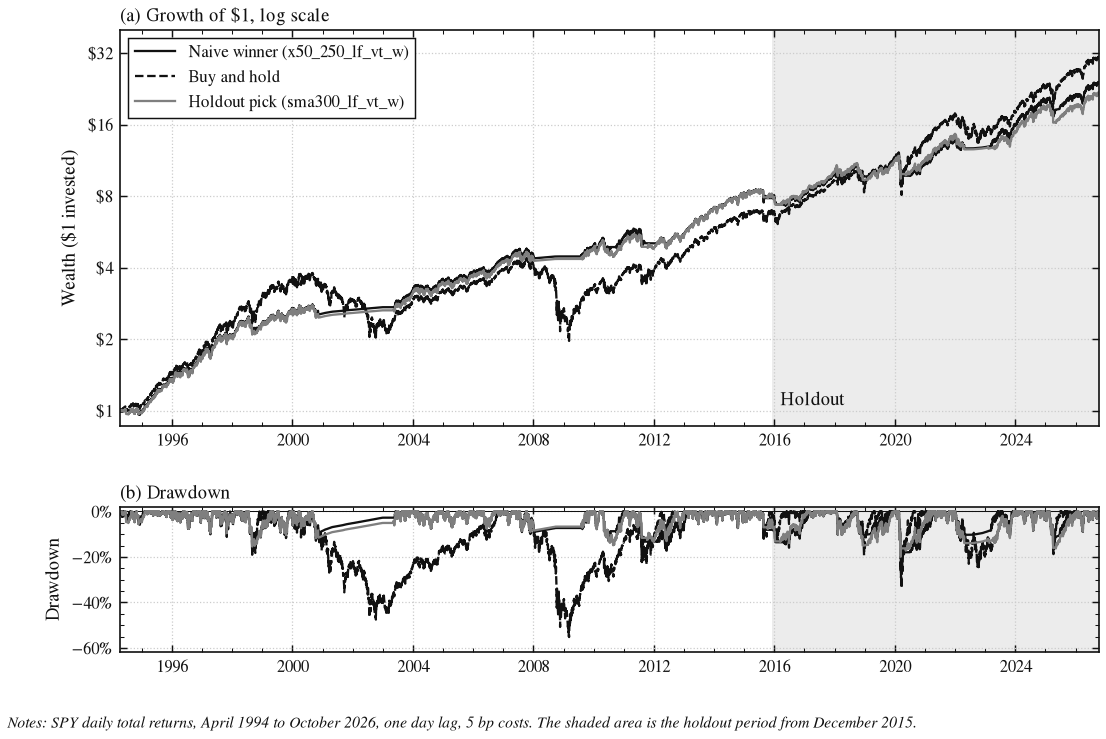

In [12]:
fig, (ax_w, ax_dd) = acad.wealth_drawdown_figure(
    totals,
    table=False,
    recessions=None,
    note="Notes: SPY daily total returns, April 1994 to October 2026, one day lag, 5 bp costs. The shaded area is the holdout period from December 2015.",
)
acad.shade(ax_w, hold["split_date"], excess.index[-1])
acad.shade(ax_dd, hold["split_date"], excess.index[-1])
ax_w.annotate(
    "Holdout",
    (hold["split_date"], 0.04),
    xycoords=("data", "axes fraction"),
    xytext=(4, 0),
    textcoords="offset points",
    va="bottom",
)
acad.save(fig, "f4_wealth", outdir=OUTPUT_DIR)
plt.show()

**Figure 3.** Trend timing avoided the big crashes, but buy and hold ended with more wealth.

**Reading the chart.** Both trend rules went sideways through the 2000 to 2002 and 2008 crashes while buy and hold fell, and at the start of the holdout they were ahead (7.8 against 6.8 dollars). After 2015 the biggest falls were short and sharp (late 2018, early 2020) and were followed by fast rebounds. The rules exited after most of the damage was done and came back after the rebound, and buy and hold ended clearly ahead: 30.9 against 24.1 dollars. Their worst moment was the 2020 crash ($-20\%$ against $-34\%$ for buy and hold).

### 4.7 Robustness: a slower execution and higher costs

The whole referee runs again with a two day lag and with 10 bp costs. Does the winner change? Does the verdict?

In [13]:
def referee_row(lag, cost_bps):
    """Rerun the full referee with other execution assumptions; one summary row."""
    out = pipeline.run_referee(
        trials,
        returns,
        project=PROJECT,
        data_label=TICKER,
        rf=rf,
        lag=lag,
        cost_bps=cost_bps,
        n_blocks=N_BLOCKS,
        alpha=ALPHA,
    )
    rep = out["report"]
    return pd.Series(
        {
            "winner": out["selected"],
            "Sharpe": rep["sr_ann"],
            "hurdle SR0": rep["sr0_ann"]["raw"],
            "DSR raw N": rep["dsr"]["raw"],
            "DSR avg corr": rep["dsr"]["avg_corr"],
            "DSR eigen": rep["dsr"]["eigen"],
            "PBO": rep["pbo"]["pbo"],
            "verdict": rep["verdict"],
        },
        name=f"lag {lag}, {cost_bps:.0f} bp",
    )


baseline = referee_row(LAG, COST_BPS)
robustness = pd.DataFrame(
    [baseline] + [referee_row(lag, cost) for lag, cost in ROBUSTNESS]
)
robustness["same winner"] = robustness["winner"] == baseline["winner"]
display(
    robustness.style.format(
        {c: "{:.2f}" for c in ["Sharpe", "hurdle SR0", "PBO"]}
        | {c: "{:.3f}" for c in ["DSR raw N", "DSR avg corr", "DSR eigen"]}
    )
)

,winner,Sharpe,hurdle SR0,DSR raw N,DSR avg corr,DSR eigen,PBO,verdict,same winner
"lag 1, 5 bp",x50_250_lf_vt_w,0.68,0.65,0.579,0.720,0.998,0.10,Not distinguishable from luck,True
"lag 2, 5 bp",x50_250_lf_vt_d,0.68,0.62,0.640,0.767,0.999,0.19,Not distinguishable from luck,False
"lag 1, 10 bp",x50_250_lf_vt_w,0.68,0.71,0.444,0.609,0.998,0.07,Not distinguishable from luck,True


**Reading the table.** With a two day lag the winner changes to the daily version of the same rule (`x50_250_lf_vt_d`), with the same Sharpe ratio. With 10 bp costs the winner stays, but the hurdle rises to 0.70 and is now *above* the winner: costs hurt the fast rules most, which spreads the trials' Sharpe ratios further apart. The verdict is the same in all three runs. Only the eigenvalue count of effective trials (2.5) would turn it into "Strong", in every run.

### 4.8 The report file

Everything above, in the eight sections of PLAN.md, is written to `output/p01/report.md`. The interpretation is written after the run and labelled as such.

In [14]:
INTERPRETATION = """*Written by Claude Code after the run, on 2026-10-11, without changing the trial family, the sample or the thresholds.*

The best of 256 trend timing rules on SPY, a 50/250 day moving average crossover that is long or in cash and scaled to 15% volatility, shows a Sharpe ratio of 0.68 over 32.5 years, against 0.53 for buy and hold, with a worst drawdown of 20% instead of 55%. Reported on its own, with a t statistic near 4, that looks like a strong result.

It does not survive the referee. The best of 256 tries would be expected to look about this good by luck alone (hurdle 0.65), so the deflated Sharpe ratio is only 0.58. The holdout points the same way: chosen on 1994 to 2015, the best rule fell behind buy and hold afterwards (0.65 against 0.75), and buy and hold ended with more wealth over the full period.

What does hold up is a broader and older finding: slow, long/flat trend rules beat fast or long/short ones (PBO 0.10), and they cut deep drawdowns in long bear markets, at the price of lower average returns and of missing fast rebounds. That is a risk management property, not a Sharpe ratio edge we can bank on.

How sure we are depends on how many independent tries the 256 trials represent. Counted as 256 or 105, the result is not distinguishable from luck; counted as 2.5, it would be strong. The hurdle also treats the genuine gap between long/flat and long/short rules as luck, which makes it strict. These are judgment calls, and they were fixed before the run.

Plain answer: if you want lower drawdowns, a slow trend filter is a reasonable tool. If you want a higher Sharpe ratio than buy and hold, this backtest is not evidence for it.
"""


def to_markdown(frame):
    """A DataFrame as a markdown table (values formatted as shown)."""
    header = "| " + " | ".join([""] + [str(c) for c in frame.columns]) + " |"
    rule = "| " + " | ".join(["---"] * (len(frame.columns) + 1)) + " |"
    rows = [
        "| " + " | ".join([str(i)] + [str(v) for v in row]) + " |"
        for i, row in zip(frame.index, frame.to_numpy(), strict=True)
    ]
    return "\n".join([header, rule, *rows])


def caveats():
    """Caveats generated from the data and the results."""
    items = [
        f"{TICKER} adjusted closes include reinvested dividends, so this is a total return index, not a price index.",
        f"Risk free rate: Ken French daily one month T bill rate, rounded to 0.01% a day and carried forward for the last {n_rf_filled} trading days.",
        "The trial family contains famous rules (200 day average, 12 month momentum) that became famous because they worked in the past; the true search was larger than 256.",
        f"Daily returns are autocorrelated: the Newey West t statistic ({report['t_nw']:.2f}) differs from the iid one ({report['t_iid']:.2f}).",
        "The referee tests against zero excess return. A long/flat rule is invested most of the time, so much of its Sharpe ratio is the equity premium that buy and hold earns too.",
    ]
    return "\n".join(f"* {item}" for item in items)

In [15]:
setup = f"""* Data: {TICKER} daily returns {returns.index[0]:%Y-%m-%d} to {returns.index[-1]:%Y-%m-%d} (Yahoo Finance, adjusted close)
* Common sample after warmup: {excess.index[0]:%Y-%m-%d} to {excess.index[-1]:%Y-%m-%d}, T = {len(excess):,} days
* Trials: {excess.shape[1]} in this run, {run["n_ledger"]} in the ledger for `{run["data_id"]}`
* Execution: lag {LAG} day, costs {COST_BPS:.0f} bp per unit of turnover
* Risk free rate: Ken French daily one month T bill"""
sections = {
    "1. Setup": setup,
    "2. Buy and hold against the naive winner": to_markdown(
        side_by_side.map(lambda v: f"{v:.3f}")
    ),
    "3. Referee table": referee_md.rsplit("\n\n**Verdict", 1)[0],
    "4. Verdict": f"**{report['verdict']}.**",
    "5. Holdout": to_markdown(holdout_table),
    "6. Robustness": to_markdown(
        robustness.map(lambda v: f"{v:.3f}" if isinstance(v, float) else v)
    ),
    "7. Caveats": caveats(),
    "8. Interpretation (written after the run)": INTERPRETATION.strip(),
}
report_md = (
    "# Project 1 referee report\n\n"
    + "\n\n".join(f"## {title}\n\n{body}" for title, body in sections.items())
    + "\n"
)
(OUTPUT_DIR / "report.md").write_text(report_md)
print(f"Wrote {OUTPUT_DIR / 'report.md'} ({len(report_md.splitlines())} lines)")

Wrote /Users/franz/Desktop/quant_finance/output/p01/report.md (93 lines)


## 5. Conclusions

1. **The naive winner is not distinguishable from luck.** Its Sharpe ratio of 0.68 barely clears the hurdle of 0.65 that 256 useless tries would reach, DSR 0.58. This holds with a two day lag and with 10 bp costs.
2. **The holdout confirms it.** Picked on 1994 to 2015, the best rule earned 0.65 afterwards, below buy and hold (0.75), rank 80 of 256.
3. **The type of rule is real, the specific rule is not.** Slow, long/flat trend rules beat the rest of the family (PBO 0.10) and halve the worst drawdown, but they earn less than buy and hold.
4. **The answer depends on the trial count.** With 2.5 effective trials the verdict would be strong. The rule to count all 256 was fixed in advance and is kept.

> **Caveats:** one index, one period; the risk free rate is coarse and carried forward for 28 days; the referee tests against zero excess return, not against buy and hold. See `output/p01/report.md`.

**Next step:** Phase 5 adds your own rules and shows how every new idea raises the trial count.

## 6. Appendix: environment

In [16]:
versions = {
    "python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "matplotlib": matplotlib.__version__,
    "quantlab": version("quantlab"),
}
print(", ".join(f"{k} {v}" for k, v in versions.items()))

python 3.12.11, numpy 2.5.4, pandas 3.0.6, matplotlib 3.11.2, quantlab 0.1.0
